In [1]:
import pandas as pd

GICS_SECTORS = [
    'Energy',
    'Materials',
    'Industrials',
    'Consumer Discretionary',
    'Consumer Staples',
    'Health Care',
    'Financials',
    'Information Technology',
    'Communication Services',
    'Utilities',
    'Real Estate'
]

EU = {
    "Germany","France","Netherlands","Italy","Spain","Poland","Ireland","Luxembourg","Belgium",
    "Denmark","Sweden","Portugal","Austria","Hungary","Czech Republic","Finland","Greece",
    "Cyprus","Estonia","Lithuania","Malta","Romania"
}

G20 = {
    "United States","Saudi Arabia","China","Germany","Japan","United Kingdom","Brazil","France","India",
    "Italy","Canada","Australia","Mexico","South Korea","Turkey","Indonesia","South Africa","Argentina"
}

BRICS = {"Brazil","Russia","India","China","South Africa","Saudi Arabia"} 

In [2]:
import pandas as pd

MAIN_DATA_SET = r".\unique_org_info_pipeline_multi_ns_enriched_combined.csv"

original_df = pd.read_csv(MAIN_DATA_SET)

eu_df = original_df[original_df['country_name'].isin(EU)]
g20_df = original_df[original_df['country_name'].isin(G20)]
brics_df = original_df[original_df['country_name'].isin(BRICS)]  

#contar numero de dominios e soma de receita por pais, sem função
original_country_summary = original_df.groupby('country_name').agg(
    num_domains=('domain', 'nunique'),
    total_revenue=('revenue', 'sum')
).sort_values('total_revenue', ascending=False).reset_index()
eu_country_summary = eu_df.groupby('country_name').agg(
    num_domains=('domain', 'nunique'),
    total_revenue=('revenue', 'sum')
).sort_values('total_revenue', ascending=False).reset_index()
g20_country_summary = g20_df.groupby('country_name').agg(
    num_domains=('domain', 'nunique'),
    total_revenue=('revenue', 'sum')
).sort_values('total_revenue', ascending=False).reset_index()
brics_country_summary = brics_df.groupby('country_name').agg(
    num_domains=('domain', 'nunique'),
    total_revenue=('revenue', 'sum')
).sort_values('total_revenue', ascending=False).reset_index()

#contar numero de dominios e soma de receita por setor gics, sem função
original_gics_summary = original_df.groupby('sector').agg(
    num_domains=('domain', 'nunique'),
    total_revenue=('revenue', 'sum')
).sort_values('total_revenue', ascending=False).reset_index()
eu_gics_summary = eu_df.groupby('sector').agg(
    num_domains=('domain', 'nunique'),
    total_revenue=('revenue', 'sum')
).sort_values('total_revenue', ascending=False).reset_index()
g20_gics_summary = g20_df.groupby('sector').agg(
    num_domains=('domain', 'nunique'),
    total_revenue=('revenue', 'sum')
).sort_values('total_revenue', ascending=False).reset_index()
brics_gics_summary = brics_df.groupby('sector').agg(
    num_domains=('domain', 'nunique'),
    total_revenue=('revenue', 'sum')
).sort_values('total_revenue', ascending=False).reset_index()   

display(original_country_summary.head(10))
display(eu_country_summary.head(10))
display(brics_country_summary.head(10))

display(original_gics_summary.head(10))
display(eu_gics_summary.head(10))
display(brics_gics_summary.head(10))

,country_name,num_domains,total_revenue
0,United States,3155,2.232454e+13
1,China,505,7.323128e+12
2,Japan,717,5.683208e+12
3,Germany,360,2.858817e+12
4,United Kingdom,454,2.541873e+12
5,France,322,2.188749e+12
6,India,613,1.890149e+12
7,Canada,394,1.639646e+12
8,South Korea,117,1.513438e+12
9,Switzerland,212,1.246645e+12


,country_name,num_domains,total_revenue
0,Germany,360,2.858817e+12
1,France,322,2.188749e+12
2,Netherlands,62,8.104870e+11
3,Spain,107,7.220742e+11
4,Italy,142,6.970639e+11
5,Sweden,203,5.361266e+11
6,Ireland,46,4.808479e+11
7,Denmark,60,2.756985e+11
8,Poland,105,2.503437e+11
9,Belgium,71,2.243088e+11


,country_name,num_domains,total_revenue
0,China,505,7.323128e+12
1,India,613,1.890149e+12
2,Brazil,82,8.078755e+11
3,Saudi Arabia,262,7.791665e+11
4,South Africa,49,2.540743e+11


,sector,num_domains,total_revenue
0,Industrials,1559,9.913682e+12
1,Financials,1561,9.698019e+12
2,Energy,653,7.628282e+12
3,Consumer Discretionary,953,7.516055e+12
4,Information Technology,1652,6.594586e+12
5,Consumer Staples,456,5.264820e+12
6,Health Care,999,5.137059e+12
7,Materials,959,4.720016e+12
8,Communication Services,370,3.136595e+12
9,Real Estate,704,1.029678e+12


,sector,num_domains,total_revenue
0,Industrials,344,2.312217e+12
1,Financials,208,1.636474e+12
2,Consumer Discretionary,172,1.482859e+12
3,Energy,96,1.232429e+12
4,Materials,170,8.773840e+11
5,Consumer Staples,70,6.158414e+11
6,Information Technology,297,5.189757e+11
7,Communication Services,82,4.935414e+11
8,Health Care,154,4.436067e+11
9,Utilities,18,1.700473e+11


,sector,num_domains,total_revenue
0,Energy,96,2.391396e+12
1,Financials,239,2.038387e+12
2,Industrials,221,1.918261e+12
3,Consumer Discretionary,184,1.258279e+12
4,Materials,242,1.086670e+12
5,Information Technology,220,8.921597e+11
6,Consumer Staples,71,5.600678e+11
7,Communication Services,57,3.900763e+11
8,Health Care,106,2.465306e+11
9,Real Estate,57,1.753748e+11


In [3]:
import pandas as pd

# Supondo que g20_df já foi filtrado
current_scope_df = g20_df.copy()

# 1️⃣ Somar métricas básicas por org_id
current_top_orgid = (
    current_scope_df.groupby('org_id')
    .agg(
        revenue_total=('revenue', 'sum'),
        domain_count=('domain', 'nunique'),
        country=('country', 'first'),
        org_name=('org_name', 'first')
    )
    .reset_index()
    .sort_values(by='revenue_total', ascending=False)
)

# 2️⃣ Calcular métricas relativas e índices de concentração
# Receita total e total de domínios na amostra
total_revenue = current_top_orgid['revenue_total'].sum()
total_domains = current_top_orgid['domain_count'].sum()

# Percentual de receita e domínios
current_top_orgid['revenue_share'] = current_top_orgid['revenue_total'] / total_revenue
current_top_orgid['domain_share'] = current_top_orgid['domain_count'] / total_domains

current_top_orgid.sort_values(by='revenue_share', ascending=False, inplace=True)

# HHI (Herfindahl–Hirschman Index) base
current_top_orgid['hhi_revenue'] = (current_top_orgid['revenue_share'] ** 2) * 10000
current_top_orgid['hhi_domain'] = (current_top_orgid['domain_share'] ** 2) * 10000
# valor de HHI total (soma de todos os HHI individuais)
hhi_revenue_total = current_top_orgid['hhi_revenue'].sum()
hhi_domain_total = current_top_orgid['hhi_domain'].sum()
print(f"HHI Receita Total: {hhi_revenue_total:.2f}")
print(f"HHI Domínio Total: {hhi_domain_total:.2f}")

# calcular HHI agrupado por país de origem da organização
current_top_orgid['country'] = current_top_orgid['country'].fillna('Unknown')
current_top_orgid = current_top_orgid.sort_values(by='revenue_total', ascending=False)


display(current_top_orgid.head(30))



HHI Receita Total: 506.51
HHI Domínio Total: 602.89


,org_id,revenue_total,domain_count,country,org_name,revenue_share,domain_share,hhi_revenue,hhi_domain
458,ORG-AT1-RIPE,8.242079e+12,359,NL,Akamai International B.V.,0.158530,0.047119,251.316989,22.202044
770,SSL-1134-ARIN,4.820039e+12,474,US,"Vercara, LLC",0.092710,0.062213,85.950678,38.704435
235,CLOUD14-ARIN,4.320222e+12,1324,US,"Cloudflare, Inc.",0.083096,0.173776,69.049481,301.981281
144,AMAZON-4-ARIN,3.296053e+12,867,US,"Amazon.com, Inc.",0.063397,0.113794,40.191726,129.491794
408,MSFT,1.980804e+12,299,US,Microsoft Corporation,0.038099,0.039244,14.515477,15.400912
357,JNIC1-AP,1.442538e+12,243,JP,Japan Network Information Center,0.027746,0.031894,7.698442,10.172240
425,NSONE-ARIN,1.435624e+12,91,US,NSONE Inc,0.027613,0.011944,7.624818,1.426549
790,TIGGE-ARIN,1.224365e+12,178,US,Tiggee LLC,0.023550,0.023363,5.545872,5.458132
304,GOGL-ARIN,7.917473e+11,90,US,Google LLC,0.015229,0.011813,2.319110,1.395369
568,ORG-IGFI3-RIPE,7.915309e+11,110,AT,ipcom GmbH,0.015224,0.014438,2.317843,2.084440


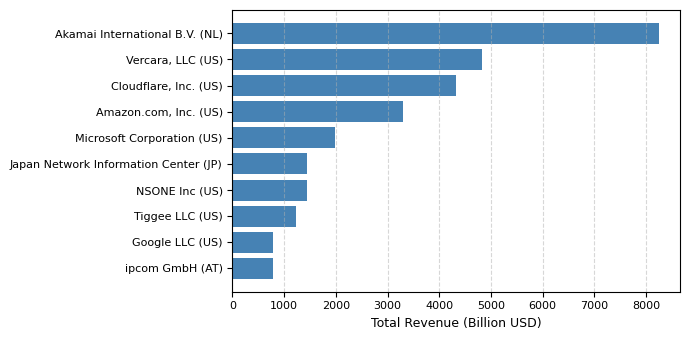

In [4]:
# gerar gráfico de barras horizontal com as top 10 org_id por revenue_total usando "org_name (country)" no eixo y e revenue_total no eixo x
import matplotlib.pyplot as plt
# Selecionar top 10
top_10_orgs = current_top_orgid.head(10)

# Figura padronizada para formato IEEE (duas colunas)
plt.figure(figsize=(7, 3.5))  # 7 inches wide = double column IEEE width

# Plot
plt.barh(
    top_10_orgs['org_name'] + ' (' + top_10_orgs['country'] + ')',
    top_10_orgs['revenue_total'] / 1e9,
    color='steelblue'
)

# Títulos e rótulos
plt.xlabel('Total Revenue (Billion USD)', fontsize=9)
plt.gca().invert_yaxis()

# Layout IEEE-friendly
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()

plt.show()

In [5]:
#list all diferent orgnames from org_name column in original_df and save in a txt file

unique_org_names = original_df['org_name'].dropna().unique()

with open('unique_org_names.txt', 'w') as f:
    for name in unique_org_names:
        f.write(name + '\n')